Install the library to download datasets from zenodo.

In [ ]:
!pip install zenodo-get

In [ ]:
import os
import re
import pickle
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt

from zenodo_get import download
from tqdm import tqdm

from keras.preprocessing.sequence import pad_sequences
from keras.applications.efficientnet import EfficientNetB0
from keras.models import Model
from keras.layers import Bidirectional, GRU, Dense, Embedding, Layer
from keras.losses import SparseCategoricalCrossentropy
from keras.metrics import Mean
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping

In [3]:
download("10.5281/zenodo.56198", output_dir='./dataset') # it may take a couple of minutes

2026-09-30 07:56:36.011 | INFO     | zenodo_get.workflow.run_download:run_download:49 - Output directory: /content/dataset
2026-09-30 07:56:38.055 | INFO     | zenodo_get.workflow.log_record_summary:log_record_summary:17 - Title: im2latex-100k ,  arXiv:1609.04938
2026-09-30 07:56:38.059 | INFO     | zenodo_get.workflow.log_record_summary:log_record_summary:24 - Total size: 306.8 MB
2026-09-30 07:56:38.060 | INFO     | zenodo_get.workflow.log_record_summary:log_record_summary:25 - Number of files: 6
2026-09-30 07:59:35.997 | SUCCESS  | zenodo_get.workflow.download_files:download_files:64 - All specified files have been processed.


In [4]:
!tar -xzf ./dataset/formula_images.tar.gz -C ./dataset

Store all file names in a dictionary for convenience.

In [5]:
DATASET_DIR = "./dataset"
dataset_files = {filename: os.path.join(DATASET_DIR, filename) for filename in os.listdir(DATASET_DIR)}

There is an important point in the dataset description:: *Newlines used in formulas_im2latex.lst are UNIX-style newlines(\n). Reading file with other type of newlines results to slightly wrong amount of lines (104563 instead of 103558), and thus breaks the structure used by this dataset.*

It is critical to specify the correct newline parameter, otherwise the formulas will go out of sync with the images.

In [6]:
with open(dataset_files['im2latex_formulas.lst'], 'r', encoding='latin-1', newline='\n') as f:
    all_formulas = [line.strip() for line in f.readlines()]

print(f"Total formulas: {len(all_formulas)}")

Total formulas: 103559


Check the readme file.

In [7]:
with open(dataset_files['readme.txt'], 'r', encoding='utf-8') as f:
    print(f.read())

Structure

- im2latex_[...].lst files
    - Each line is separate generated image per formula
    - Line structure: "[formula_idx] [image_name] [render_type]"
        - formula_idx is the line number of the formula in im2latex_formulas.lst
        - image_name is the name of rendered image (without '.png')
        - render_type is the name of used rendering settings (in image2latex.py)
    - Dataset is split to train, validation and test
        - train is for training the model
        - validation is for things testing accuracy while training / checking overfitting
        - test set is for final evaluation 
- im2latex_formulas.lst
    - Each line is a separate formula (formulas were stripped from "\n")
- formula_images.tar.gz
    - tar file of the rendered images
    - Each image is an image of full "A4" page, where _only_ the formula is rendered
        - -> Lots of empty space



Each .lst file acts as a router that defines how to assemble the dataset. It consists of lines where each line contains two values: the first is the formula index, and the second is the image name without extension.

In [8]:
def create_dataset(router_file):
    images = list()
    formulas = list()

    with open(router_file, 'r', encoding='utf-8') as f:
        for line in f:
            formula_idx, image_name, _ = line.strip().split(' ')

            if formula_idx and image_name:
                image_path = os.path.join(dataset_files['formula_images'], image_name + '.png')
                formula = all_formulas[int(formula_idx)]

                images.append(image_path)
                formulas.append(formula)

    return images, formulas

In [9]:
train_imgs, train_formulas = create_dataset(dataset_files['im2latex_train.lst'])
val_imgs, val_formulas = create_dataset(dataset_files['im2latex_validate.lst'])
test_imgs, test_formulas = create_dataset(dataset_files['im2latex_test.lst'])

print(f"Train set size: {len(train_imgs)} images and {len(train_formulas)} formulas")
print(f"Validation set size: {len(val_imgs)} images and {len(val_formulas)} formulas")
print(f"Test set size: {len(test_imgs)} images and {len(test_formulas)} formulas")

Train set size: 83884 images and 83884 formulas
Validation set size: 9320 images and 9320 formulas
Test set size: 10355 images and 10355 formulas


In [10]:
TRAIN_SIZE = 30000
VAL_SIZE = 5000
TEST_SIZE = 5000

train_imgs = train_imgs[:TRAIN_SIZE]
train_formulas = train_formulas[:TRAIN_SIZE]

val_imgs = val_imgs[:VAL_SIZE]
val_formulas = val_formulas[:VAL_SIZE]

test_imgs = test_imgs[:TEST_SIZE]
test_formulas = test_formulas[:TEST_SIZE]

print(f"Train: {len(train_imgs)} | Val: {len(val_imgs)} | Test: {len(test_imgs)} | Total: {len(train_imgs) + len(val_imgs) + len(test_imgs)}")

Train: 30000 | Val: 5000 | Test: 5000 | Total: 40000


Plot a sample image and its corresponding formula.

Image size: 2339x1654
Corresponding formula:
[W_2] = i_{C_2*}\left(3l' - E'_2 - \dots - E'_9\right)\label{badex}


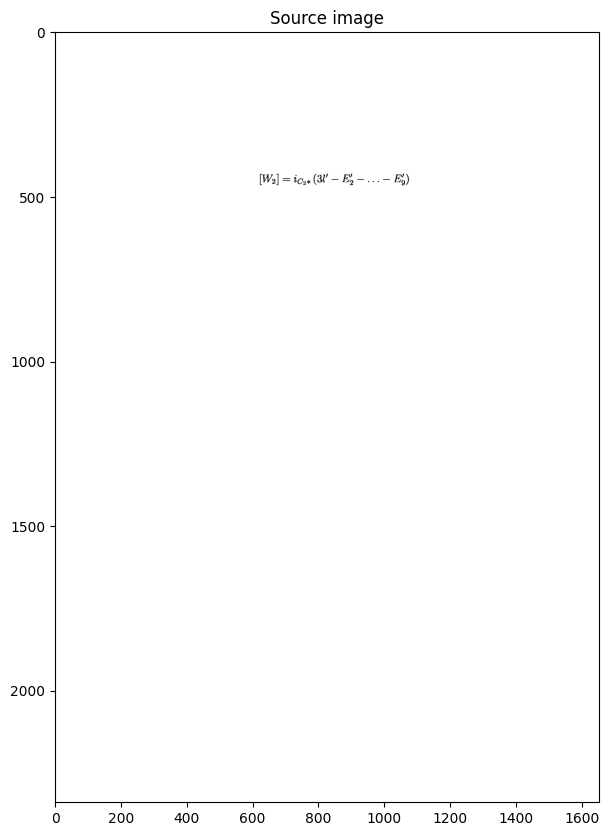

In [11]:
sample_image_raw = tf.io.read_file(train_imgs[25000])
sample_image = tf.image.decode_png(sample_image_raw, channels=1)

print(f"Image size: {sample_image.shape[0]}x{sample_image.shape[1]}")
print(f"Corresponding formula:")
print(train_formulas[25000])

plt.figure(figsize=(8, 10))
plt.imshow(sample_image[:, :, 0], cmap='gray')

plt.title("Source image")
plt.axis('on')

plt.show()

The formulas are written in small text on a large A4 sheet. We need to crop the text and apply padding to the top and bottom keeping the width uniform.

In [12]:
def crop_image(image_path, padding=15):
    raw_img = tf.io.read_file(image_path)
    img = tf.image.decode_png(raw_img, channels=1) # (2339, 1654, 1)

    # Invert pixel values so the text becomes white and background becomes black
    inverted = tf.math.subtract(tf.constant(255, dtype=tf.uint8), img)

    # Reduce image to one flat vertical vector and get a boolean mask
    row_has_text = tf.reduce_any(inverted > 0, axis=1)[:, 0]
    # Extract the vertical indices of all rows that contain at least one text pixel
    text_rows = tf.where(row_has_text)

    # Find the first row index where text begins and cast it to a 32-bit integer
    y_min = tf.cast(tf.reduce_min(text_rows), tf.int32)
    # Find the last row index where text ends and cast it to a 32-bit integer
    y_max = tf.cast(tf.reduce_max(text_rows), tf.int32)

    img_height = tf.shape(img)[0]

    # Add paddings safely to a cropped text
    top = tf.maximum(0, y_min - padding)
    bottom = tf.minimum(img_height, y_max + padding)

    cropped_img = img[top:bottom, :, :]
    return cropped_img

Try to crop some images.

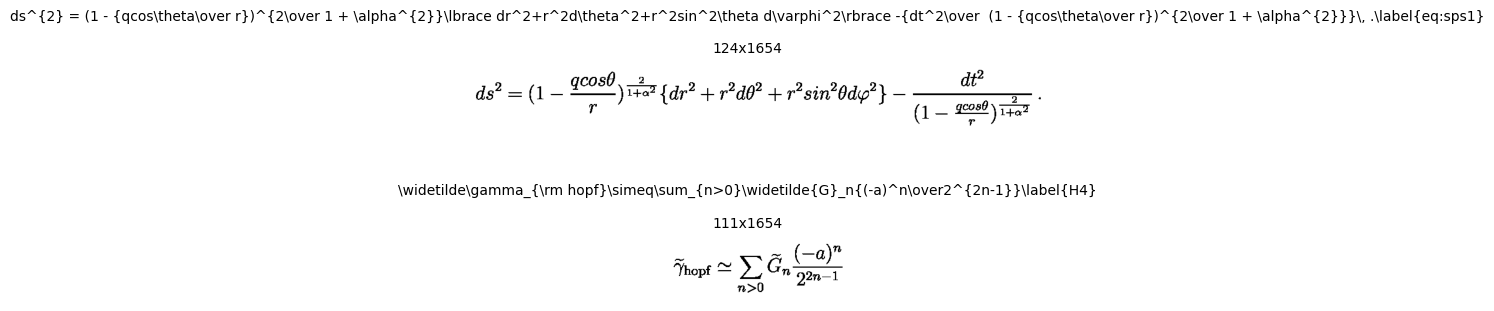

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(10, 4))

for i in range(2):
    img_path = train_imgs[i]
    cropped_img = crop_image(img_path, padding=15)

    title = f"{train_formulas[i]}\n\n{cropped_img.shape[0]}x{cropped_img.shape[1]}"

    axes[i].set_title(title, fontsize=10)
    axes[i].imshow(cropped_img, cmap='gray')
    axes[i].axis('off')

plt.tight_layout()
plt.show()

Define the image width as a constant.

In [14]:
MAX_WIDTH = 1654

Analyze the heights of all images by cropping them and gathering all height values into a single list.

In [15]:
all_paths = train_imgs + val_imgs + test_imgs

In [ ]:
all_heights = [crop_image(path).shape[0] for path in tqdm(all_paths)]

100%|██████████| 40000/40000 [24:14<00:00, 27.51it/s]


In [ ]:
with open("all_heights.pkl", "wb") as f:
    pickle.dump(all_heights, f)

In [19]:
print(pd.Series(all_heights).describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99, 0.999, 0.9999]))

count     40000.000000
mean         94.399775
std          32.816489
min          15.000000
50%          97.000000
75%         109.000000
90%         117.000000
95%         129.000000
99%         212.000000
99.9%       402.006000
99.99%      661.000700
max        1485.000000
dtype: float64


The statistics show that the most of the images have a standard height. It is interesting to investigate why some formula images have anomalous heights.

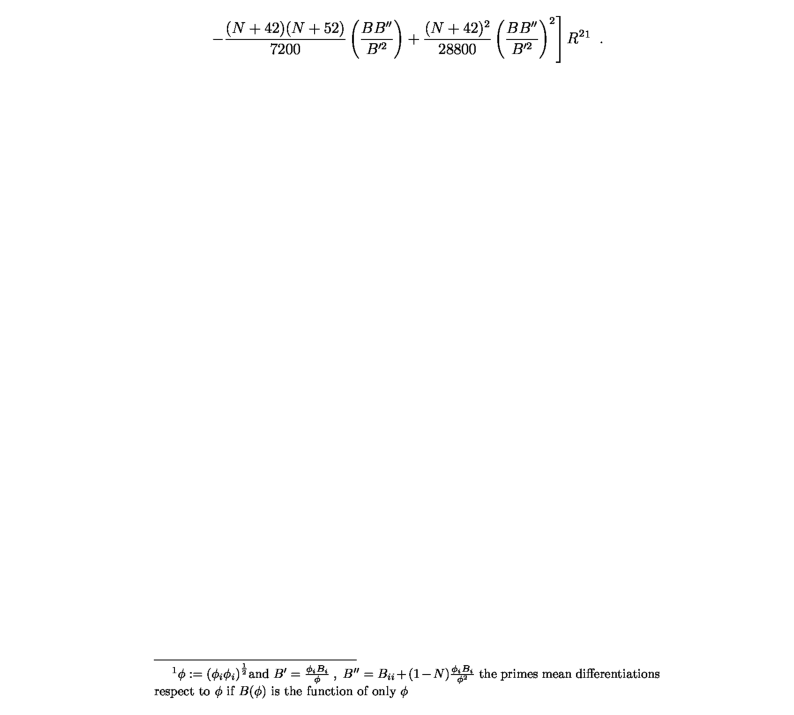

In [20]:
anomaly_height = max(all_heights)

anomaly_index = all_heights.index(anomaly_height)
anomaly_path = all_paths[anomaly_index]
anomaly_tensor = crop_image(anomaly_path)

plt.figure(figsize=(10, 10))

plt.imshow(anomaly_tensor.numpy().squeeze(), cmap='gray')
plt.axis('off')
plt.show()

Filter the datasets by standard, correct heights.

In [21]:
MIN_HEIGHT = 40
MAX_HEIGHT = 160

train_heights = all_heights[:TRAIN_SIZE]
val_heights   = all_heights[TRAIN_SIZE : TRAIN_SIZE + VAL_SIZE]
test_heights  = all_heights[TRAIN_SIZE + VAL_SIZE :]

train_imgs_clean, train_formulas_clean = zip(*[
    (img, form) for img, form, h in zip(train_imgs, train_formulas, train_heights)
    if MIN_HEIGHT <= h <= MAX_HEIGHT
])

val_imgs_clean, val_formulas_clean = zip(*[
    (img, form) for img, form, h in zip(val_imgs, val_formulas, val_heights)
    if MIN_HEIGHT <= h <= MAX_HEIGHT
])

test_imgs_clean, test_formulas_clean = zip(*[
    (img, form) for img, form, h in zip(test_imgs, test_formulas, test_heights)
    if MIN_HEIGHT <= h <= MAX_HEIGHT
])

train_imgs_clean, train_formulas_clean = list(train_imgs_clean), list(train_formulas_clean)
val_imgs_clean, val_formulas_clean     = list(val_imgs_clean), list(val_formulas_clean)
test_imgs_clean, test_formulas_clean   = list(test_imgs_clean), list(test_formulas_clean)

print(f"Train: {len(train_imgs)} -> {len(train_imgs_clean)}")
print(f"Val: {len(val_imgs)} -> {len(val_imgs_clean)}")
print(f"Test: {len(test_imgs)} -> {len(test_imgs_clean)}")

Train: 30000 -> 29275
Val: 5000 -> 4880
Test: 5000 -> 4864


Write a function to remove the trailing service label from each formula, tokenize it using a regular expression, and wrap it with start-of-sequence and end-of-sequence tokens.

In [22]:
def tokenize_formula(formula: str) -> list:
    formula = re.sub(r'\\label\{.*?\}', '', formula)

    pattern = r"\\(?:[a-zA-Z]+|[^a-zA-Z])|[{}]|[^\\{}\s]|\s+"
    tokens = re.findall(pattern, formula)

    tokens = [t for t in tokens if t.strip()]
    return ["<sos>"] + tokens + ["<eos>"]

In [23]:
train_formulas_tokenized = [tokenize_formula(f) for f in train_formulas_clean]
val_formulas_tokenized = [tokenize_formula(f) for f in val_formulas_clean]
test_formulas_tokenized = [tokenize_formula(f) for f in test_formulas_clean]

In [24]:
tokenizer = tf.keras.preprocessing.text.Tokenizer(filters='', lower=False, oov_token="<unk>")
tokenizer.fit_on_texts(train_formulas_tokenized)

In [25]:
train_formulas_sequenced = tokenizer.texts_to_sequences(train_formulas_tokenized)
val_formulas_sequenced = tokenizer.texts_to_sequences(val_formulas_tokenized)
test_formulas_sequenced = tokenizer.texts_to_sequences(test_formulas_tokenized)

VOCAB_SIZE = len(tokenizer.word_index) + 1

In [26]:
print(f"Vocabulary size: {VOCAB_SIZE}")
print(f"First tokens: {list(tokenizer.word_index.items())[:25]}")
print(f"Source formula: {train_formulas_clean[0]}")
print(f"Tokenized formula: {train_formulas_tokenized[0]}")
print(f"Sequenced formula: {train_formulas_sequenced[0]}")

Vocabulary size: 580
First tokens: [('<unk>', 1), ('}', 2), ('{', 3), ('_', 4), ('^', 5), (')', 6), ('(', 7), ('2', 8), ('1', 9), ('-', 10), ('=', 11), (',', 12), ('<sos>', 13), ('<eos>', 14), ('+', 15), ('i', 16), ('\\frac', 17), ('a', 18), ('0', 19), ('x', 20), ('r', 21), ('.', 22), ('d', 23), ('\\,', 24), ('n', 25)]
Source formula: ds^{2} = (1 - {qcos\theta\over r})^{2\over 1 + \alpha^{2}}\lbrace dr^2+r^2d\theta^2+r^2sin^2\theta d\varphi^2\rbrace -{dt^2\over  (1 - {qcos\theta\over r})^{2\over 1 + \alpha^{2}}}\, .\label{eq:sps1}
Tokenized formula: ['<sos>', 'd', 's', '^', '{', '2', '}', '=', '(', '1', '-', '{', 'q', 'c', 'o', 's', '\\theta', '\\over', 'r', '}', ')', '^', '{', '2', '\\over', '1', '+', '\\alpha', '^', '{', '2', '}', '}', '\\lbrace', 'd', 'r', '^', '2', '+', 'r', '^', '2', 'd', '\\theta', '^', '2', '+', 'r', '^', '2', 's', 'i', 'n', '^', '2', '\\theta', 'd', '\\varphi', '^', '2', '\\rbrace', '-', '{', 'd', 't', '^', '2', '\\over', '(', '1', '-', '{', 'q', 'c', 'o', 's',

In [27]:
SOS_TOKEN_IDX = tokenizer.word_index.get("<sos>")
EOS_TOKEN_IDX = tokenizer.word_index.get("<eos>")

Filter the formulas by the maximum target width and pad the sequences with zeros using pad_sequences.

In [28]:
all_formula_lengths = (
    [len(seq) for seq in train_formulas_sequenced] +
    [len(seq) for seq in val_formulas_sequenced] +
    [len(seq) for seq in test_formulas_sequenced]
)

print(pd.Series(all_formula_lengths).describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99, 0.999, 0.9999]))

count     39019.000000
mean         58.055998
std          32.664023
min           6.000000
50%          50.000000
75%          73.000000
90%         100.000000
95%         119.000000
99%         163.000000
99.9%       249.982000
99.99%      464.347000
max         730.000000
dtype: float64


In [29]:
MAX_TOKEN_LEN = 120

train_imgs_final, train_sequences_raw = zip(*[
    (img, seq) for img, seq in zip(train_imgs_clean, train_formulas_sequenced)
    if len(seq) <= MAX_TOKEN_LEN
])

val_imgs_final, val_sequences_raw = zip(*[
    (img, seq) for img, seq in zip(val_imgs_clean, val_formulas_sequenced)
    if len(seq) <= MAX_TOKEN_LEN
])

test_imgs_final, test_sequences_raw = zip(*[
    (img, seq) for img, seq in zip(test_imgs_clean, test_formulas_sequenced)
    if len(seq) <= MAX_TOKEN_LEN
])

train_imgs_final, train_sequences_pad = list(train_imgs_final), pad_sequences(
    train_sequences_raw, maxlen=MAX_TOKEN_LEN, padding='post'
)

val_imgs_final, val_sequences_pad = list(val_imgs_final), pad_sequences(
    val_sequences_raw, maxlen=MAX_TOKEN_LEN, padding='post'
)

test_imgs_final, test_sequences_pad = list(test_imgs_final), pad_sequences(
    test_sequences_raw, maxlen=MAX_TOKEN_LEN, padding='post'
)

print(f"Train images: {len(train_imgs_final)} | Train sequences: {train_sequences_pad.shape}")
print(f"Val images: {len(val_imgs_final)} | Val sequences: {val_sequences_pad.shape}")
print(f"Test images: {len(test_imgs_final)} | Test sequences: {test_sequences_pad.shape}")

Train images: 27876 | Train sequences: (27876, 120)
Val images: 4647 | Val sequences: (4647, 120)
Test images: 4648 | Test sequences: (4648, 120)


Make a final check to ensure images and formulas match.

Corresponding formula:
<sos> q = ( q _ 1 + v ) | \mathbf { w } ^ 1 \rangle + \sum _ { a = 2 } ^ { 7 } { q _ a | \mathbf { w } ^ a \rangle } . <eos>


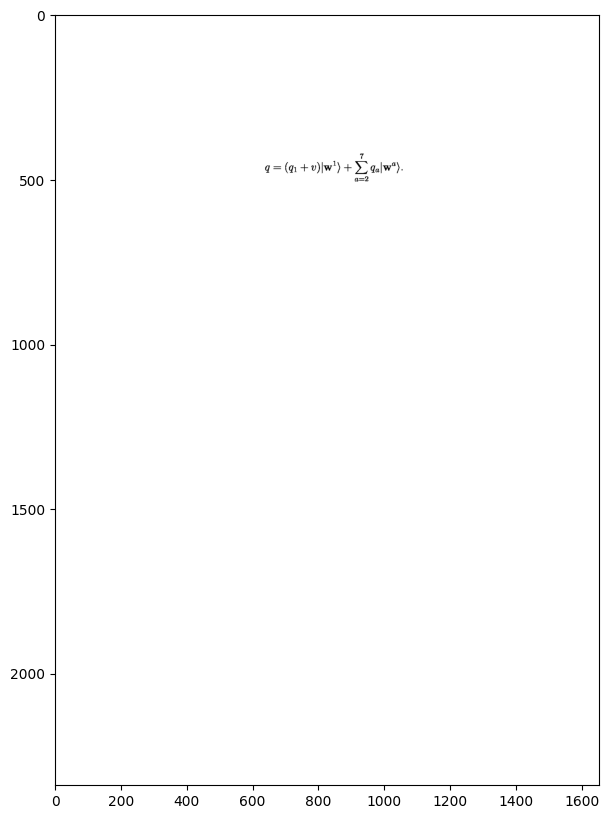

In [30]:
check_idx = -4

check_img_path = train_imgs_final[check_idx]
check_token_ids = train_sequences_pad[check_idx]

check_tokens = [tokenizer.index_word[idx] for idx in check_token_ids if idx in tokenizer.index_word]
check_formula = " ".join(check_tokens)

check_raw_img = tf.io.read_file(check_img_path)
check_img = tf.image.decode_png(check_raw_img, channels=1)

print("Corresponding formula:")
print(check_formula)

plt.figure(figsize=(8, 10))
plt.imshow(check_img.numpy().squeeze(), cmap='gray')

plt.axis('on')
plt.show()

Prepare the datasets for model training.

In [31]:
def create_tf_dataset(image_paths, padded_sequences, batch_size, is_training=True):
    dataset = tf.data.Dataset.from_tensor_slices((image_paths, padded_sequences))

    if is_training:
        dataset = dataset.shuffle(buffer_size=1000)

    dataset = dataset.map(prepare_tf_data, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(batch_size, drop_remainder=True)
    dataset = dataset.prefetch(buffer_size=tf.data.AUTOTUNE)

    return dataset

In [32]:
def prepare_tf_data(image_path, formula):
    cropped_img = crop_image(image_path)

    # Pad image to the constant height of 160 -> (160, 1654, 1)
    pad_h = tf.maximum(0, MAX_HEIGHT - tf.shape(cropped_img)[0])
    padded_img = tf.pad(
        cropped_img,
        paddings=[[0, pad_h], [0, 0], [0, 0]],
        mode='CONSTANT',
        constant_values=255
    )

    padded_img.set_shape([MAX_HEIGHT, MAX_WIDTH, 1])

    rgb_image = tf.image.grayscale_to_rgb(padded_img) # (160, 1654, 3)
    processed_image = tf.cast(rgb_image, tf.float32)

    decoder_input = formula[:-1]
    decoder_target = formula[1:]

    return {"image_input": processed_image, "decoder_input": decoder_input}, decoder_target

In [33]:
BATCH_SIZE = 32

train_dataset = create_tf_dataset(
    train_imgs_final,
    train_sequences_pad,
    batch_size=BATCH_SIZE,
    is_training=True
)

val_dataset = create_tf_dataset(
    val_imgs_final,
    val_sequences_pad,
    batch_size=BATCH_SIZE,
    is_training=False
)

test_dataset = create_tf_dataset(
    test_imgs_final,
    test_sequences_pad,
    batch_size=BATCH_SIZE,
    is_training=False
)

Check the output feature shape with a dummy batch.

In [34]:
dummy_batch = tf.zeros((1, MAX_HEIGHT, MAX_WIDTH, 3))

test_extractor = EfficientNetB0(
    include_top=False,
    weights=None,
    input_shape=(MAX_HEIGHT, MAX_WIDTH, 3)
)

features = test_extractor(dummy_batch)
print("Tensor shape:", features.shape)

Tensor shape: (1, 5, 52, 1280)


In [35]:
EMBEDDING_DIM = 256
ENC_UNITS = 256
DEC_UNITS = 512

The encoder uses a pre-trained EfficientNetB0 to extract features from the final conv layer. It reshapes the features into 52 timesteps, passes them through a dense layer into a bidirectional GRU and returns the full sequence of hidden states and the concatenated forward and backward hidden states.

In [ ]:
class LatexEncoder(Layer):
    def __init__(self, enc_units):
        super(LatexEncoder, self).__init__()

        base_model = EfficientNetB0(
            include_top=False,
            weights='imagenet',
            input_shape=(MAX_HEIGHT, MAX_WIDTH, 3)
        )
        base_model.trainable = False

        self.efficientnet = base_model
        self.dense = Dense(enc_units, activation='relu')
        self.rnn = Bidirectional(GRU(enc_units, return_sequences=True, return_state=True))

    def call(self, x):
        # x:        [batch_size, 160, 1654, 3]
        # features: [batch_size, 5, 52, 1280]
        features = self.efficientnet(x)

        _, height, width, channels = features.shape

        # [batch_size, 5, 52, 1280] -> [batch_size, 52, 5, 1280]
        features = tf.transpose(features, perm=[0, 2, 1, 3])
        # [batch_size, 52, 5 * 1280] -> [batch_size, 52, 6400]
        features = tf.reshape(features, (-1, width, height * channels))

        # [batch_size, 52, enc_units]
        features = self.dense(features)

        # output: [batch_size, 52, enc_units * 2]
        # forward_state, backward_state: [batch_size, enc_units]
        output, forward_state, backward_state = self.rnn(features)

        # state: [batch_size, enc_units * 2]
        state = tf.concat([forward_state, backward_state], axis=-1)

        return output, state

Use the Bahdanau attention to calculate the attention context vector.

In [ ]:
class BahdanauAttention(Layer):
    def __init__(self, units):
        super(BahdanauAttention, self).__init__()

        self.W1 = Dense(units)
        self.W2 = Dense(units)
        self.V = Dense(1)

    def call(self, query, values):
        # query:  [batch_size, dec_units]
        # values: [batch_size, 52, enc_units * 2]

        # [batch_size, dec_units] -> [batch_size, 1, dec_units]
        query_with_time_axis = tf.expand_dims(query, axis=1)

        # W1(query):  [batch_size, 1, units]
        # W2(values): [batch_size, 52, units]
        # score: [batch_size, 52, 1]
        score = self.V(tf.nn.tanh(self.W1(query_with_time_axis) + self.W2(values)))

        # attention_weights: [batch_size, 52, 1]
        attention_weights = tf.nn.softmax(score, axis=1)

        # context_vector: [batch_size, 52, enc_units * 2]
        context_vector = attention_weights * values

        # context_vector: [batch_size, enc_units * 2]
        context_vector = tf.reduce_sum(context_vector, axis=1)

        return context_vector, attention_weights

The decoder takes a token as input, generates its embedding and computes the attention context vector. It then concatenates the context vector with the input token embedding and passes it to the GRU layer. It returns the probability distribution for the current token and its updated hidden state.

In [ ]:
class LatexDecoder(Layer):
    def __init__(self, vocab_size, embedding_dim, dec_units):
        super(LatexDecoder, self).__init__()

        self.attention = BahdanauAttention(dec_units)
        self.embedding = Embedding(vocab_size, embedding_dim)
        self.gru = GRU(dec_units, return_sequences=True, return_state=True)
        self.dense = Dense(vocab_size)

    def call(self, x, hidden, enc_output):
        # x:          [batch_size, 1]
        # hidden:     [batch_size, dec_units]
        # enc_output: [batch_size, 52, enc_units * 2]

        # context_vector:    [batch_size, enc_units * 2]
        # attention_weights: [batch_size, 52, 1]
        context_vector, attention_weights = self.attention(query=hidden, values=enc_output)

        # x: [batch_size, 1, embedding_dim]
        x = self.embedding(x)

        # context_vector: [batch_size, enc_units * 2] -> [batch_size, 1, enc_units * 2]
        context_vector_expanded = tf.expand_dims(context_vector, axis=1)

        # x: [batch_size, 1, embedding_dim + enc_units * 2]
        x = tf.concat([context_vector_expanded, x], axis=-1)

        # output: [batch_size, 1, dec_units]
        # state:  [batch_size, dec_units]
        output, state = self.gru(x, initial_state=hidden)

        # output: [batch_size, dec_units]
        output = tf.squeeze(output, axis=1)

        # predictions: [batch_size, vocab_size]
        predictions = self.dense(output)

        return predictions, state, attention_weights

Create a model class with methods for training, validation, and prediction.

In [39]:
class Img2LatexModel(Model):
    def __init__(self, vocab_size, embedding_dim, enc_units, dec_units):
        super(Img2LatexModel, self).__init__()

        self.encoder = LatexEncoder(enc_units)
        self.decoder = LatexDecoder(vocab_size, embedding_dim, dec_units)

        self.loss_func = SparseCategoricalCrossentropy(from_logits=True, reduction='none')
        self.loss_metric = Mean(name='loss')
        self.val_loss_metric = Mean(name='val_loss')

    def calculate_loss(self, real, pred):
        """
        Masks the pad token (0) so it doesn't affect the loss.
        Returns the sum of all losses and number of non-padded tokens
        """
        loss_ = self.loss_func(real, pred)

        mask = tf.math.logical_not(tf.math.equal(real, 0))
        mask = tf.cast(mask, dtype=loss_.dtype)

        loss_ *= mask
        return tf.reduce_sum(loss_), tf.reduce_sum(mask)

    @tf.function
    def train_step(self, data):
        x_data, y_true = data
        img_input = x_data['image_input']
        dec_input = x_data['decoder_input']

        max_target_len = tf.shape(dec_input)[1]

        with tf.GradientTape() as tape:
            enc_output, dec_hidden = self.encoder(img_input)

            total_loss = tf.constant(0.0)
            total_tokens = tf.constant(0.0)
            for t in tf.range(max_target_len):
                current_input = tf.expand_dims(dec_input[:, t], 1)
                predictions, dec_hidden, _ = self.decoder(current_input, dec_hidden, enc_output)

                step_loss, step_tokens = self.calculate_loss(y_true[:, t], predictions)
                total_loss += step_loss
                total_tokens += step_tokens

            # Add epsilon to prevent division by zero
            batch_loss = total_loss / (total_tokens + 1e-7)

        variables = self.trainable_variables
        gradients = tape.gradient(batch_loss, variables)

        self.optimizer.apply_gradients(zip(gradients, variables))

        self.loss_metric.update_state(batch_loss)
        return {"loss": self.loss_metric.result()}

    @tf.function
    def test_step(self, data):
        x_data, y_true = data
        img_input = x_data['image_input']
        dec_input = x_data['decoder_input']

        enc_output, dec_hidden = self.encoder(img_input)
        max_target_len = tf.shape(dec_input)[1]

        total_loss = tf.constant(0.0)
        total_tokens = tf.constant(0.0)
        for t in range(max_target_len):
            current_input = tf.expand_dims(dec_input[:, t], 1)
            predictions, dec_hidden, _ = self.decoder(current_input, dec_hidden, enc_output)

            step_loss, step_tokens = self.calculate_loss(y_true[:, t], predictions)
            total_loss += step_loss
            total_tokens += step_tokens

        batch_loss = total_loss / (total_tokens + 1e-7)

        self.val_loss_metric.update_state(batch_loss)
        return {"loss": self.val_loss_metric.result()}

    @property # Enables Keras to correctly log metrics during training
    def metrics(self):
        return [self.loss_metric, self.val_loss_metric]

    def predict_latex(self, image, start_token_idx, end_token_idx):
        img_input = tf.expand_dims(image, axis=0)

        enc_output, dec_hidden = self.encoder(img_input)
        dec_input = tf.expand_dims([start_token_idx], 0)

        predicted_sequence = []
        for t in range(MAX_TOKEN_LEN):
            predictions, dec_hidden, _ = self.decoder(dec_input, dec_hidden, enc_output)
            predicted_id = tf.argmax(predictions[0]).numpy()

            if predicted_id == end_token_idx:
                break

            predicted_sequence.append(predicted_id)
            dec_input = tf.expand_dims([predicted_id], 0)

        return predicted_sequence

In [40]:
def init_model(lr):
    model = Img2LatexModel(
        vocab_size=VOCAB_SIZE,
        embedding_dim=EMBEDDING_DIM,
        enc_units=ENC_UNITS,
        dec_units=DEC_UNITS
    )

    model.compile(optimizer=Adam(learning_rate=lr))
    return model

In [ ]:
model = init_model(1e-4)

In [ ]:
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=10,
    verbose=1
)

Epoch 1/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1224s 1s/step - loss: 3.5298 - val_loss: 2.9499
Epoch 2/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1207s 1s/step - loss: 2.7152 - val_loss: 2.5019
Epoch 3/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1178s 1s/step - loss: 2.3709 - val_loss: 2.2464
Epoch 4/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1279s 1s/step - loss: 2.1414 - val_loss: 2.0647
Epoch 5/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1202s 1s/step - loss: 1.9826 - val_loss: 1.9273
Epoch 6/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1202s 1s/step - loss: 1.8761 - val_loss: 1.8387
Epoch 7/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1236s 1s/step - loss: 1.8036 - val_loss: 1.7977
Epoch 8/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1212s 1s/step - loss: 1.6855 - val_loss: 1.6663
Epoch 9/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1222s 1s/step - loss: 1.6011 - val_loss: 1.6107
Epoch 10/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1212s 1s/step - loss: 1.5279 - val_loss: 1.5637


Save optimizer and model states

In [ ]:
checkpoint = tf.train.Checkpoint(
    optimizer=model.optimizer,
    encoder=model.encoder,
    decoder=model.decoder
)
checkpoint.write('./img2latex')

Restore optimizer and model states.

In [42]:
inputs, targets = next(iter(test_dataset.take(1)))

single_img = inputs["image_input"][0][tf.newaxis, ...]
dec_input = inputs["decoder_input"][0][tf.newaxis, ...]

current_token = dec_input[:, 0:1]
enc_output, enc_state = model.encoder(single_img)

_, _, _ = model.decoder(
    x=current_token,
    hidden=enc_state,
    enc_output=enc_output
)

checkpoint = tf.train.Checkpoint(
    optimizer=model.optimizer,
    encoder=model.encoder,
    decoder=model.decoder
)
status = checkpoint.restore('./img2latex')
status.expect_partial()

In [ ]:
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=10,
    verbose=1
)

Epoch 1/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1349s 2s/step - loss: 1.4669 - val_loss: 1.5071
Epoch 2/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1251s 1s/step - loss: 1.4066 - val_loss: 1.4464
Epoch 3/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1269s 1s/step - loss: 1.3773 - val_loss: 1.4111
Epoch 4/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1293s 1s/step - loss: 1.3078 - val_loss: 1.3791
Epoch 5/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1284s 1s/step - loss: 1.2639 - val_loss: 1.3422
Epoch 6/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1276s 1s/step - loss: 1.2331 - val_loss: 1.3221
Epoch 7/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1284s 1s/step - loss: 1.1903 - val_loss: 1.3037
Epoch 8/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1256s 1s/step - loss: 1.1622 - val_loss: 1.2828
Epoch 9/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1218s 1s/step - loss: 1.1213 - val_loss: 1.2556
Epoch 10/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1191s 1s/step - loss: 1.0974 - val_loss: 1.2380


In [ ]:
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=10,
    verbose=1
)

Epoch 1/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1217s 1s/step - loss: 1.0738 - val_loss: 1.2211
Epoch 2/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1238s 1s/step - loss: 1.0355 - val_loss: 1.2008
Epoch 3/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1202s 1s/step - loss: 1.0116 - val_loss: 1.1855
Epoch 4/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1232s 1s/step - loss: 0.9913 - val_loss: 1.1884
Epoch 5/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1196s 1s/step - loss: 0.9739 - val_loss: 1.1710
Epoch 6/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1212s 1s/step - loss: 0.9419 - val_loss: 1.1706
Epoch 7/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1195s 1s/step - loss: 0.9218 - val_loss: 1.1695
Epoch 8/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1224s 1s/step - loss: 0.8985 - val_loss: 1.1488
Epoch 9/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1213s 1s/step - loss: 0.8841 - val_loss: 1.1449
Epoch 10/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1211s 1s/step - loss: 0.8625 - val_loss: 1.1363


In [ ]:
model = init_model(1e-5)

In [43]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=10,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1227s 1s/step - loss: 0.8431 - val_loss: 1.1353
Epoch 2/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1178s 1s/step - loss: 0.8221 - val_loss: 1.1274
Epoch 3/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1253s 1s/step - loss: 0.8333 - val_loss: 1.1215
Epoch 4/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1206s 1s/step - loss: 0.7818 - val_loss: 1.1159
Epoch 5/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1203s 1s/step - loss: 0.7685 - val_loss: 1.1244
Epoch 6/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1202s 1s/step - loss: 0.8071 - val_loss: 1.1137
Epoch 7/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1243s 1s/step - loss: 0.7352 - val_loss: 1.1127
Epoch 8/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1211s 1s/step - loss: 0.7177 - val_loss: 1.1236
Epoch 9/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1198s 1s/step - loss: 0.7100 - val_loss: 1.1225
Epoch 10/10
871/871 ━━━━━━━━━━━━━━━━━━━━ 1198s 1s/step - loss: 0.7020 - val_loss: 1.1237
Restoring model weights from the end of the best epoch: 7.


Try to generate five formulas from the test dataset.

In [45]:
inputs, targets = next(iter(test_dataset.take(1)))

test_img = inputs["image_input"]
test_seq = targets.numpy()

num_examples = 5

for i in range(num_examples):
    single_img = test_img[i]
    source_formula_indices = test_seq[i]

    predicted_indices = model.predict_latex(
        single_img,
        start_token_idx=SOS_TOKEN_IDX,
        end_token_idx=EOS_TOKEN_IDX
    )

    real_latex = " ".join([tokenizer.index_word.get(idx, "<unk>") for idx in source_formula_indices if idx != 0])
    predicted_latex = " ".join([tokenizer.index_word.get(idx, "<unk>") for idx in predicted_indices if idx != 0])

    print(f"Formula {i+1}")
    print(f"Real formula: {real_latex}")
    print(f"Predicted formula {predicted_latex}")
    if i != num_examples - 1: print("")

Formula 1
Real formula: \alpha _ 1 ^ r \gamma _ 1 + \dots + \alpha _ N ^ r \gamma _ N = 0 \quad ( r = 1 , . . . , R ) \; , <eos>
Predicted formula \alpha ^ i q _ 1 + \cdots + \alpha _ f ^ * \gamma _ { N - N } = \quad ( r = 1 , . . . , 7 ) \, ,

Formula 2
Real formula: \eta = - \frac { 1 } { 2 } \ln \left ( \frac { \cosh \left ( \sqrt { 2 } b _ \infty \sqrt { 1 + \alpha ^ 2 } \; y - { \rm a r c s i n h } \; \alpha \right ) } { \sqrt { 1 + \alpha ^ 2 } } \right ) <eos>
Predicted formula \eta = - \frac { 1 } { 2 } \ln \left ( \frac { \cosh ( z \sqrt { 2 } \alpha \sqrt { 1 + \alpha ^ 2 } - \cosh 2 \alpha ) \alpha } { \sqrt { 1 + \alpha ^ 2 } } \right ) \right )

Formula 3
Real formula: P _ { ( 2 ) } ^ - = \int \beta d \beta d ^ 9 p d ^ 8 \lambda \Phi ( - p , - \lambda ) \left ( - \frac { p ^ I p ^ I } { 2 \beta } \right ) \Phi ( p , \lambda ) \, . <eos>
Predicted formula P ( g ) = \int d \beta d \theta d p ^ 2 d \Phi ^ 2 ( - p - 2 ) \left ( \frac { k ^ 2 L ^ 2 } { R ^ 2 } \right ) \Phi ( x